# F1. Risque de crédit en Allemagne
**LAMRINI FATIMA**   **Code Apogée :** 25007655 **Groupe :** FIN 3
**Filière :** S7 FIN **Date :** 17/11/2026
**Dépôt GitHub :** https://github.com/Fatima5730/25007655-FATIMA-LAMRINI-FIN3

## 1. Sujet et problématique
- **Intérêt du sujet** : Un analyste crédit doit décider d'accepter ou de refuser un prêt. Refuser un bon client fait perdre des intérêts, accepter un mauvais risque fait perdre du capital : un modèle de scoring aide à prendre cette décision de façon cohérente.
- **Problématique** : À partir des caractéristiques d'un client et de son prêt, une régression logistique détecte-t-elle les mauvais risques mieux qu'une règle naïve, et quel seuil de décision minimise le coût lorsque accepter un mauvais risque coûte 5 fois plus que refuser un bon client ?
- **Objectif mesurable** : Métrique principale : AUC en validation croisée stratifiée à 5 plis. Référence : classifieur naïf (classe majoritaire, AUC = 0,5). Jeu de test : 30 % des clients, utilisé une seule fois. Seuil de réussite : [AUC ≥ 0,70 sur le test et coût total au seuil optimal inférieur d'au moins 20 % au coût obtenu au seuil de 0,5].
- **Nature du problème** : Classification binaire (0 = bon risque, 1 = mauvais risque), classes déséquilibrées (environ 70 % / 30 %) et coûts d'erreur asymétriques.
- **Algorithme principal envisagé** : n° 8, régression logistique.

## 2. Jeu de données
- **Nom et source** : Statlog (German Credit Data), UCI Machine Learning Repository, n° 144. Lien : https://archive.ics.uci.edu/dataset/144
- **Date d'extraction** : 17/11/2026
- **Licence** : This dataset is licensed under a Creative Commons Attribution 4.0 International (CC BY 4.0) license.
- **Taille** : 1 000 observations, 20 variables explicatives (7 numériques, 13 catégorielles) et une cible.
- **Période et fréquence** : la documentation ne précise pas de période et le fichier ne contient aucune date : ce sont des données en coupe transversale, sans dimension temporelle.
- **Unité d'observation** : une ligne = un dossier de demande de crédit d'un client.
- **Variable cible** : `risque` (1 = bon risque, 2 = mauvais risque), recodée à l'étape de préparation en 0 (bon) et 1 (mauvais).
- **Adéquation** : chaque dossier porte son issue connue (bon ou mauvais risque), ce qui permet un apprentissage supervisé pour répondre à la problématique.
- **Limites** : jeu petit (1 000 dossiers) et ancien, montants en marks allemands (DM) ; 30 % de mauvais risques seulement ; on ignore comment les dossiers ont été sélectionnés (biais de sélection possible) ; absence de date, donc aucun test de robustesse dans le temps ; variables sensibles (statut personnel et sexe, travailleur étranger) ; les coûts d'erreur ne sont pas dans les données, c'est une hypothèse.


In [35]:
# Récupération du dépôt dans l'environnement Colab
!git clone https://github.com/Fatima5730/25007655-FATIMA-LAMRINI-FIN3.git
%cd 25007655-FATIMA-LAMRINI-FIN3

Cloning into '25007655-FATIMA-LAMRINI-FIN3'...
remote: Enumerating objects: 134, done.
remote: Counting objects: 100% (134/134), done.
remote: Compressing objects: 100% (122/122), done.
remote: Total 134 (delta 48), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (134/134), 21.57 MiB | 17.78 MiB/s, done.
Resolving deltas: 100% (48/48), done.
/content/25007655-FATIMA-LAMRINI-FIN3/25007655-FATIMA-LAMRINI-FIN3


In [36]:
# Configuration : imports, graine, chemins relatifs, versions
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

GRAINE = 42
np.random.seed(GRAINE)

# Chemins relatifs à la racine du dépôt (aucun chemin absolu)
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = RACINE / "data" / "raw"
DATA_PROCESSED = RACINE / "data" / "processed"
FIGURES = RACINE / "figures"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(exist_ok=True)

print("Python        :", platform.python_version())
print("numpy         :", np.__version__)
print("pandas        :", pd.__version__)
print("matplotlib    :", matplotlib.__version__)
print("scikit-learn  :", sklearn.__version__)

Python        : 3.13.18
numpy         : 2.4.6
pandas        : 2.2.3
matplotlib    : 3.10.0
scikit-learn  : 1.6.1


In [37]:
FICHIER = DATA_RAW / "german_credit.csv"
df = pd.read_csv(FICHIER)
print("Dimensions :", df.shape)
print("Colonnes :", list(df.columns))
df.head()

Dimensions : (1000, 21)
Colonnes : ['statut_compte', 'duree_mois', 'historique_credit', 'objet', 'montant', 'epargne', 'anciennete_emploi', 'taux_mensualite', 'statut_perso_sexe', 'autres_debiteurs', 'anciennete_residence', 'bien', 'age', 'autres_credits', 'logement', 'nb_credits', 'emploi', 'nb_personnes_charge', 'telephone', 'travailleur_etranger', 'risque']


,statut_compte,duree_mois,historique_credit,objet,montant,epargne,anciennete_emploi,taux_mensualite,statut_perso_sexe,autres_debiteurs,...,bien,age,autres_credits,logement,nb_credits,emploi,nb_personnes_charge,telephone,travailleur_etranger,risque
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [38]:
from pathlib import Path
Path("data/raw").mkdir(parents=True, exist_ok=True)

In [39]:
print("Fichier trouvé :", (DATA_RAW / "german_credit.csv").exists())

Fichier trouvé : True


### Dictionnaire des principales variables

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| duree_mois | Durée du crédit | numérique | mois | explicative | 0 |
| montant | Montant du crédit | numérique | DM (marks allemands) | explicative | 0 |
| age | Âge du demandeur | numérique | années | explicative | 0 |
| taux_mensualite | Mensualité en % du revenu disponible | numérique (1 à 4) | % (catégories) | explicative | 0 |
| statut_compte | Statut du compte courant | catégorielle (A11 à A14) | sans unité | explicative | 0 |
| historique_credit | Historique de crédit | catégorielle (A30 à A34) | sans unité | explicative | 0 |
| objet | Objet du crédit | catégorielle (10 modalités) | sans unité | explicative | 0 |
| risque | Bon (1) ou mauvais (2) risque | binaire | sans unité | cible | 0 |

Les 12 autres variables (épargne, ancienneté dans l'emploi, statut personnel et sexe, etc.) sont utilisées dans le modèle ; leurs codes sont définis dans la documentation UCI. La cible est recodée en 0/1 à l'étape de préparation.

## 3. Exploration
Cette section décrit les variables, vérifie la qualité des données puis présente trois graphiques reliés à la problématique : la répartition de la cible, la durée et le montant selon le profil de risque, et le statut du compte courant.

In [40]:
num_cols = df.select_dtypes(include="number").columns.drop("risque").tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print(len(num_cols), "variables numériques,", len(cat_cols), "catégorielles")
df[num_cols].describe().round(1)

7 variables numériques, 13 catégorielles


,duree_mois,montant,taux_mensualite,anciennete_residence,age,nb_credits,nb_personnes_charge
count,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
mean,20.9,3271.3,3.0,2.8,35.5,1.4,1.2
std,12.1,2822.7,1.1,1.1,11.4,0.6,0.4
min,4.0,250.0,1.0,1.0,19.0,1.0,1.0
25%,12.0,1365.5,2.0,2.0,27.0,1.0,1.0
50%,18.0,2319.5,3.0,3.0,33.0,1.0,1.0
75%,24.0,3972.2,4.0,4.0,42.0,2.0,1.0
max,72.0,18424.0,4.0,4.0,75.0,4.0,2.0


**Lecture.** Le jeu compte 7 variables numériques et 13 catégorielles. Les échelles sont très différentes : le montant va de 250 à 18 424 DM alors que la durée va de 4 à 72 mois. Le montant moyen (3 271 DM) est nettement supérieur à sa médiane (2 320 DM) : la distribution est asymétrique, avec quelques crédits très élevés. Cette différence d'échelle justifiera la standardisation (section 4).

In [41]:
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print("Lignes dupliquées  :", int(df.duplicated().sum()))

# Valeurs atypiques : règle de Tukey, au-dessus de Q3 + 1,5 × IQR
resume = []
for col in ["duree_mois", "montant", "age"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    borne = q3 + 1.5 * (q3 - q1)
    extremes = df[df[col] > borne]
    resume.append({"variable": col, "borne haute": round(borne),
                   "nb au-dessus": len(extremes), "maximum": df[col].max(),
                   "part de mauvais risques parmi eux": round((extremes["risque"] == 2).mean(), 2)})
pd.DataFrame(resume)

Valeurs manquantes : 0
Lignes dupliquées  : 0


,variable,borne haute,nb au-dessus,maximum,part de mauvais risques parmi eux
0,duree_mois,42,70,72,0.57
1,montant,7882,72,18424,0.54
2,age,64,23,75,0.26


**Qualité des données.**

| Problème | Détection | Décision | Justification |
|---|---|---|---|
| Valeurs manquantes | `isna().sum()` | Aucune action : 0 manquant | Pas d'imputation nécessaire. |
| Doublons | `duplicated().sum()` | Aucune action : 0 doublon | Chaque ligne est un dossier distinct. |
| Valeurs extrêmes (durée, montant, âge) | Règle de Tukey : au-dessus de Q3 + 1,5 × IQR | **Conservées** | Ce sont de vrais dossiers (gros crédits, longues durées). Parmi les extrêmes de durée et de montant, environ 55 % sont des mauvais risques, contre 30 % en moyenne : les supprimer ferait perdre de l'information utile. |

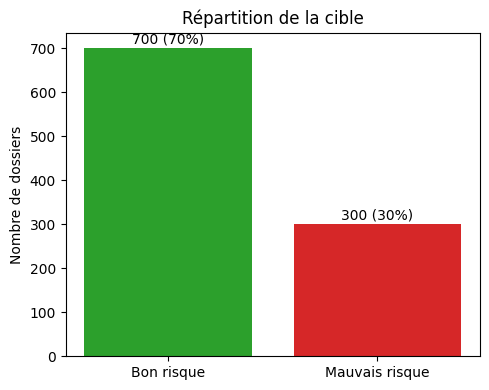

In [42]:
profil = df["risque"].map({1: "Bon risque", 2: "Mauvais risque"})
effectifs = profil.value_counts().reindex(["Bon risque", "Mauvais risque"])

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(effectifs.index, effectifs.values, color=["tab:green", "tab:red"])
for i, v in enumerate(effectifs.values):
    ax.text(i, v + 10, f"{v} ({v / len(df):.0%})", ha="center")
ax.set_title("Répartition de la cible")
ax.set_ylabel("Nombre de dossiers")
plt.tight_layout()
plt.savefig(FIGURES / "01_repartition_cible.png", dpi=150)
plt.show()

**Interprétation.** Les classes sont déséquilibrées : 700 bons risques (70 %) pour 300 mauvais risques (30 %). Conséquences : le découpage devra être stratifié, et l'exactitude serait trompeuse (accepter tout le monde donnerait déjà 70 %). La métrique principale sera donc l'AUC.

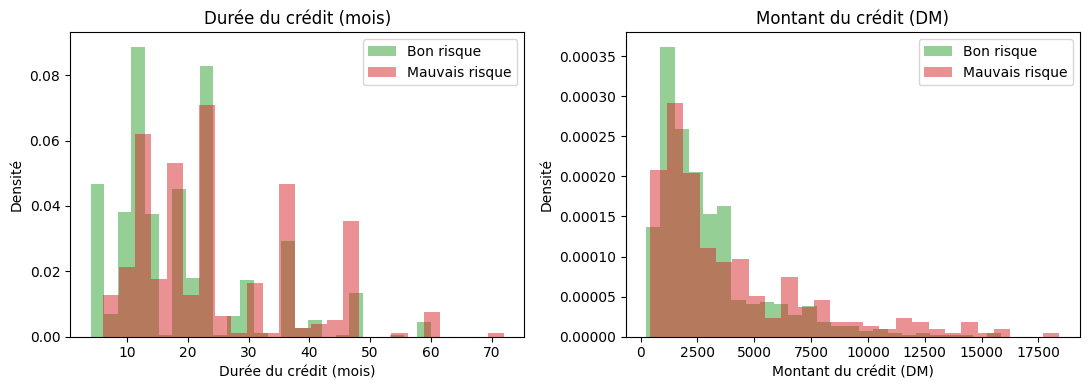

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, titre in zip(axes, ["duree_mois", "montant"],
                          ["Durée du crédit (mois)", "Montant du crédit (DM)"]):
    for valeur, nom, couleur in [(1, "Bon risque", "tab:green"), (2, "Mauvais risque", "tab:red")]:
        ax.hist(df.loc[df["risque"] == valeur, col], bins=25, alpha=0.5,
                density=True, label=nom, color=couleur)
    ax.set_title(titre)
    ax.set_xlabel(titre)
    ax.set_ylabel("Densité")
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "02_duree_montant.png", dpi=150)
plt.show()

**Interprétation.** Les mauvais risques ont en moyenne des crédits plus longs (environ 25 mois contre 19) et plus élevés (environ 3 900 DM contre 3 000), mais les distributions se chevauchent largement : aucune variable seule ne sépare les deux profils. Un modèle devra combiner plusieurs variables. Le montant est très asymétrique (longue queue à droite).

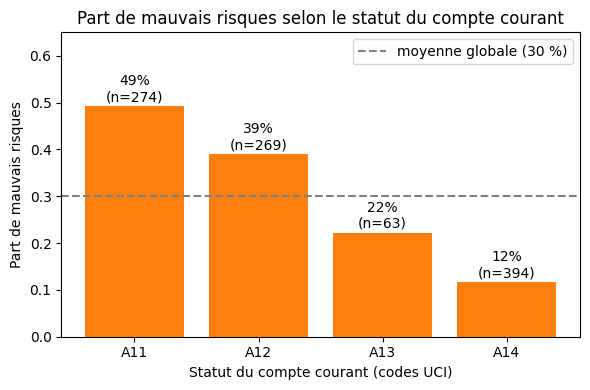

In [44]:
part = df.assign(mauvais=(df["risque"] == 2)).groupby("statut_compte")["mauvais"].mean().sort_index()
effectif = df["statut_compte"].value_counts().reindex(part.index)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(part.index, part.values, color="tab:orange")
ax.axhline((df["risque"] == 2).mean(), color="grey", linestyle="--", label="moyenne globale (30 %)")
for i, (v, n) in enumerate(zip(part.values, effectif.values)):
    ax.text(i, v + 0.01, f"{v:.0%}\n(n={n})", ha="center")
ax.set_ylim(0, 0.65)
ax.set_title("Part de mauvais risques selon le statut du compte courant")
ax.set_xlabel("Statut du compte courant (codes UCI)")
ax.set_ylabel("Part de mauvais risques")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "03_statut_compte.png", dpi=150)
plt.show()

**Interprétation.** Le statut du compte courant est très discriminant : 49 % de mauvais risques pour A11 (n = 274) et 39 % pour A12, contre 22 % pour A13 et 12 % pour A14, pour une moyenne de 30 %. Cette variable catégorielle apporte de l'information que ni la durée ni le montant ne donnent. Il s'agit d'une association statistique, pas d'une preuve de causalité.

## 4. Préparation
- **Cible** : recodée en 0 (bon risque) et 1 (mauvais risque), pour que le mauvais risque soit la classe positive.
- **Découpage** : 70 % apprentissage et 30 % test, **stratifié** pour conserver 30 % de mauvais risques dans chaque partie, avec une graine fixe. Le jeu de données n'a pas de dimension temporelle : un découpage aléatoire est donc acceptable, et aucun alignement de dates n'est nécessaire.
- **Découper avant de transformer** : le découpage est fait en premier ; toute transformation qui apprend quelque chose des données est ajustée sur l'apprentissage seulement.
- **Standardisation** des 7 variables numériques : nécessaire pour la régression logistique, car la régularisation pénalise les coefficients et dépend donc de l'échelle des variables (durée en dizaines, montant en milliers).
- **Encodage one-hot** des 13 variables catégorielles : les codes comme A11 n'ont pas d'ordre numérique.
- **Pipeline** : prétraitement et modèle dans un même `Pipeline`, pour que le prétraitement soit réajusté sur chaque pli de validation croisée.
- **Test** : utilisé une seule fois, à la fin.

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

y = (df["risque"] == 2).astype(int)        # 1 = mauvais risque (classe positive)
X = df.drop(columns="risque")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=GRAINE)

print("Apprentissage :", X_train.shape, "| Test :", X_test.shape)
print("Part de mauvais risques : apprentissage", round(y_train.mean(), 3),
      "| test", round(y_test.mean(), 3))

# Prétraitement défini ici, mais ajusté plus tard DANS le pipeline (sur l'apprentissage uniquement)
preprocesseur = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

X_train.head(3).assign(cible=y_train.head(3))

Apprentissage : (700, 20) | Test : (300, 20)
Part de mauvais risques : apprentissage 0.3 | test 0.3


,statut_compte,duree_mois,historique_credit,objet,montant,epargne,anciennete_emploi,taux_mensualite,statut_perso_sexe,autres_debiteurs,...,bien,age,autres_credits,logement,nb_credits,emploi,nb_personnes_charge,telephone,travailleur_etranger,cible
10,A12,12,A32,A40,1295,A61,A72,3,A92,A101,...,A123,25,A143,A151,1,A173,1,A191,A201,1
82,A14,18,A32,A49,1568,A62,A73,3,A92,A101,...,A122,24,A143,A151,1,A172,1,A191,A201,0
827,A14,18,A30,A49,4165,A61,A73,2,A93,A101,...,A123,36,A142,A152,2,A173,2,A191,A201,1


**Contrôle.** Le jeu d'apprentissage compte 700 dossiers et le jeu de test 300, avec la même part de mauvais risques (30 %). Le `ColumnTransformer` est seulement défini à ce stade : il sera ajusté (`fit`) à l'intérieur du pipeline, sur l'apprentissage, puis appliqué (`transform`) à la validation et au test. Aucune information du test n'est donc utilisée pour la standardisation ou l'encodage.

In [46]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Séparation des variables numériques et catégorielles
num_cols = X.select_dtypes(include=['number']).columns
cat_cols = X.select_dtypes(include=['object']).columns

# Prétraitement
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

# Construction du modèle
logistic_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42))
])

# Apprentissage
logistic_model.fit(X_train, y_train)

print("Modèle de régression logistique entraîné avec succès.")


Modèle de régression logistique entraîné avec succès.


In [47]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

params = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    logistic_model,
    params,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_model = grid.best_estimator_

print("Meilleurs paramètres :", grid.best_params_)
print("AUC moyenne :", grid.best_score_)
print("Écart-type :", grid.cv_results_['std_test_score'][grid.best_index_])


Meilleurs paramètres : {'classifier__C': 0.1, 'classifier__class_weight': None}
AUC moyenne : 0.7734207968901847
Écart-type : 0.028728092991696267


In [48]:
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict

# Obtention des probabilités hors-session sur le jeu d'apprentissage pour éviter le surapprentissage
proba_val = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

seuils = np.arange(0.01, 1, 0.01)
couts = []

for seuil in seuils:
    pred = (proba_val >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    # Coût de l'erreur d'acceptation d'un mauvais risque (FN) = 5 fois le coût d'un refus d'un bon client (FP)
    couts.append(5 * fn + fp)

best_threshold = seuils[np.argmin(couts)]

print("Seuil optimal :", round(best_threshold, 2))
print("Coût minimal estimé en validation croisée :", min(couts))

Seuil optimal : 0.22
Coût minimal estimé en validation croisée : 377


In [49]:

from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

proba_test = best_model.predict_proba(X_test)[:, 1]

pred_05 = (proba_test >= 0.5).astype(int)
pred_opt = (proba_test >= best_threshold).astype(int)

def calcul_cout(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return 5 * fn + fp

print("AUC :", roc_auc_score(y_test, proba_test))
print("Accuracy :", accuracy_score(y_test, pred_opt))
print("Precision :", precision_score(y_test, pred_opt, zero_division=0))
print("Recall :", recall_score(y_test, pred_opt, zero_division=0))
print("F1-score :", f1_score(y_test, pred_opt, zero_division=0))

cout_05 = calcul_cout(y_test, pred_05)
cout_opt = calcul_cout(y_test, pred_opt)

print("Coût avec seuil 0.5 :", cout_05)
print("Coût avec seuil optimal :", cout_opt)

if cout_05 > 0:
    print("Réduction du coût (%) :", (cout_05-cout_opt)/cout_05*100)


AUC : 0.8092063492063493
Accuracy : 0.6433333333333333
Precision : 0.4508670520231214
Recall : 0.8666666666666667
F1-score : 0.5931558935361216
Coût avec seuil 0.5 : 251
Coût avec seuil optimal : 155
Réduction du coût (%) : 38.24701195219124


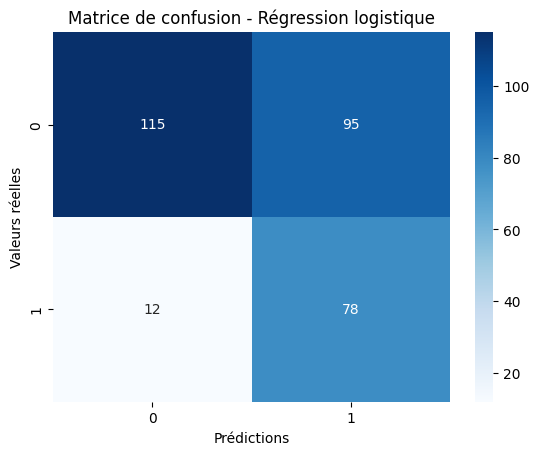

In [50]:

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, pred_opt)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.title("Matrice de confusion - Régression logistique")
plt.show()


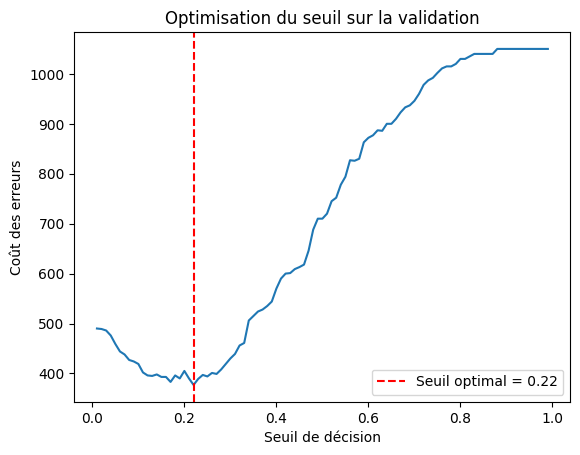

In [51]:

plt.plot(seuils, couts)
plt.axvline(best_threshold, linestyle='--', color='red',
            label=f'Seuil optimal = {best_threshold:.2f}')
plt.xlabel("Seuil de décision")
plt.ylabel("Coût des erreurs")
plt.title("Optimisation du seuil sur la validation")
plt.legend()
plt.show()


### Optimisation des hyperparamètres

L'optimisation a été réalisée à l'aide de GridSearchCV avec une validation croisée stratifiée à 5 plis, en utilisant l'AUC comme métrique principale.

Les meilleurs paramètres obtenus sont :
- C = 0,1
- class_weight = None

Le modèle a obtenu une AUC moyenne de **0,7734**, avec un écart-type de **0,0287**.

Ces résultats montrent une capacité satisfaisante à distinguer les clients présentant un bon risque de ceux présentant un mauvais risque de crédit.

In [52]:
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict

# Correction : Utilisation de cross_val_predict sur le jeu d'apprentissage à la place de X_val non défini
proba_val = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

seuils = np.arange(0.01, 1, 0.01)
couts = []

for seuil in seuils:
    predictions = (proba_val >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_train, predictions, labels=[0, 1]
    ).ravel()

    couts.append(5 * fn + fp)

best_threshold = seuils[np.argmin(couts)]

print("Seuil optimal :", round(best_threshold, 2))
print("Coût minimal :", min(couts))

Seuil optimal : 0.22
Coût minimal : 377


In [53]:
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

# Probabilités et prédictions
proba_test = best_model.predict_proba(X_test)[:, 1]

pred_05 = (proba_test >= 0.5).astype(int)
pred_opt = (proba_test >= best_threshold).astype(int)

# Fonction de calcul du coût
def calcul_cout(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    return 5 * fn + fp

# Indicateurs de performance
print("AUC :", roc_auc_score(y_test, proba_test))
print("Accuracy :", accuracy_score(y_test, pred_opt))
print("Precision :", precision_score(y_test, pred_opt, zero_division=0))
print("Recall :", recall_score(y_test, pred_opt, zero_division=0))
print("F1-score :", f1_score(y_test, pred_opt, zero_division=0))

# Comparaison des coûts
cout_05 = calcul_cout(y_test, pred_05)
cout_opt = calcul_cout(y_test, pred_opt)

print("Coût avec seuil 0.5 :", cout_05)
print("Coût avec seuil optimal :", cout_opt)

if cout_05 > 0:
    reduction = (cout_05 - cout_opt) / cout_05 * 100
    print("Réduction du coût (%) :", reduction)

# Matrice de confusion
print("Matrice de confusion :")
print(confusion_matrix(y_test, pred_opt, labels=[0, 1]))

AUC : 0.8092063492063493
Accuracy : 0.6433333333333333
Precision : 0.4508670520231214
Recall : 0.8666666666666667
F1-score : 0.5931558935361216
Coût avec seuil 0.5 : 251
Coût avec seuil optimal : 155
Réduction du coût (%) : 38.24701195219124
Matrice de confusion :
[[115  95]
 [ 12  78]]


La régression logistique obtient une AUC de 0,8092 sur l'ensemble de test, indiquant une bonne capacité de discrimination entre les bons et les mauvais clients. Le seuil de décision optimal, fixé à 0,22 à partir de l'ensemble de validation, permet d'obtenir un recall de 86,67 %. Le coût total des erreurs passe de 251 avec le seuil classique de 0,5 à 155 avec le seuil optimisé, soit une réduction de 38,25 %. Le modèle dépasse ainsi les objectifs de performance définis. Malgré un nombre relativement élevé de bons clients rejetés à tort, il permet de limiter les erreurs les plus coûteuses, à savoir l'acceptation de clients présentant un mauvais risque de crédit.

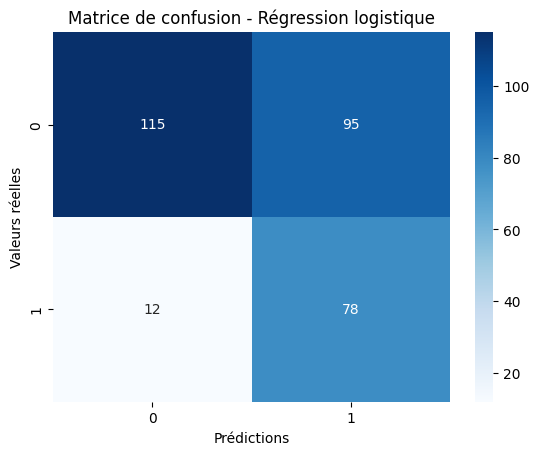

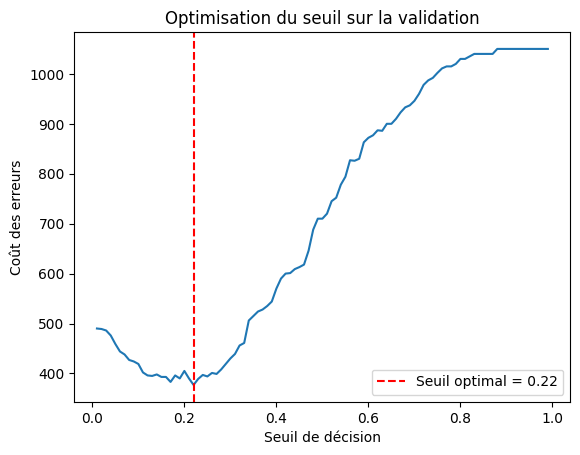

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Matrice de confusion
cm = confusion_matrix(y_test, pred_opt, labels=[0, 1])

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.title("Matrice de confusion - Régression logistique")
plt.show()

# 2. Coût selon le seuil de décision
plt.plot(seuils, couts)
plt.axvline(best_threshold, linestyle='--', color='red',
            label=f'Seuil optimal = {best_threshold:.2f}')
plt.xlabel("Seuil de décision")
plt.ylabel("Coût des erreurs")
plt.title("Optimisation du seuil sur la validation")
plt.legend()
plt.show()

In [55]:
import pandas as pd
import numpy as np

# Récupérer les noms des variables après prétraitement
feature_names = best_model.named_steps['preprocessing'].get_feature_names_out()

# Récupérer les coefficients
coefficients = best_model.named_steps['classifier'].coef_[0]

# Construire un tableau
coef_df = pd.DataFrame({
    'Variable': feature_names,
    'Coefficient': coefficients,
    'Odds_Ratio': np.exp(coefficients)
})

# Trier par importance absolue
coef_df['Importance'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values('Importance', ascending=False)

print(coef_df.head(15).to_string(index=False))

                  Variable  Coefficient  Odds_Ratio  Importance
    cat__statut_compte_A14    -0.727161    0.483279    0.727161
cat__historique_credit_A34    -0.511311    0.599709    0.511311
    cat__statut_compte_A11     0.503267    1.654116    0.503267
          cat__epargne_A61     0.471647    1.602632    0.471647
            cat__objet_A46     0.396185    1.486145    0.396185
cat__anciennete_emploi_A74    -0.382632    0.682064    0.382632
          cat__epargne_A65    -0.346463    0.707185    0.346463
            cat__objet_A41    -0.330327    0.718689    0.330327
  cat__autres_credits_A143    -0.324839    0.722644    0.324839
           num__duree_mois     0.313359    1.368012    0.313359
            cat__bien_A124     0.308112    1.360854    0.308112
  cat__autres_credits_A141     0.300684    1.350783    0.300684
      num__taux_mensualite     0.274311    1.315624    0.274311
cat__statut_perso_sexe_A93    -0.274296    0.760107    0.274296
        cat__logement_A151     0.265311 

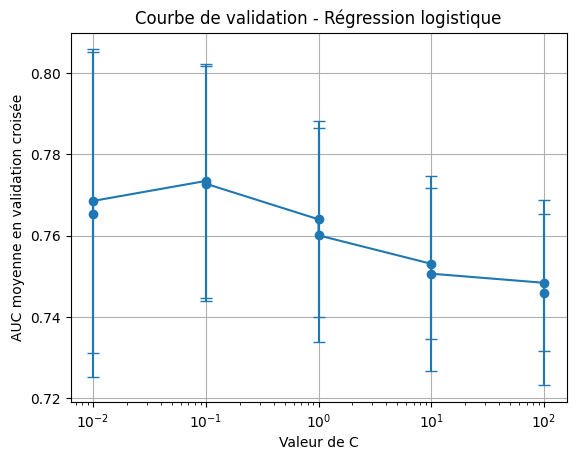

In [56]:
import matplotlib.pyplot as plt

resultats = pd.DataFrame(grid.cv_results_)

plt.errorbar(
    resultats['param_classifier__C'].astype(float),
    resultats['mean_test_score'],
    yerr=resultats['std_test_score'],
    marker='o',
    capsize=4
)

plt.xscale('log')
plt.xlabel("Valeur de C")
plt.ylabel("AUC moyenne en validation croisée")
plt.title("Courbe de validation - Régression logistique")
plt.grid(True)
plt.show()

In [57]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# Entraîner le modèle naïf sur les données d'apprentissage
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

# Prédictions sur le test
pred_baseline = baseline.predict(X_test)
proba_baseline = baseline.predict_proba(X_test)[:, 1]

# Évaluation
print("Accuracy :", accuracy_score(y_test, pred_baseline))
print("AUC :", roc_auc_score(y_test, proba_baseline))
print("Coût du modèle naïf :", calcul_cout(y_test, pred_baseline))

Accuracy : 0.7
AUC : 0.5
Coût du modèle naïf : 450


In [58]:
import os
import matplotlib.pyplot as plt

# Créer un dossier pour les figures
os.makedirs("figures", exist_ok=True)

# Exporter toutes les figures ouvertes
for numero in plt.get_fignums():
    fig = plt.figure(numero)
    fig.savefig(
        f"figures/figure_{numero}.png",
        dpi=300,
        bbox_inches="tight"
    )

print("Toutes les figures ont été exportées dans le dossier 'figures'.")

Toutes les figures ont été exportées dans le dossier 'figures'.


In [59]:
import os
import matplotlib.pyplot as plt
from pathlib import Path

# Créer un dossier sur le Bureau
dossier = Path.home() / "Desktop" / "Figures_Projet"
dossier.mkdir(parents=True, exist_ok=True)

# Exporter les figures
for i, numero in enumerate(plt.get_fignums(), start=1):
    fig = plt.figure(numero)
    fig.savefig(dossier / f"Figure_{i}.png",
                dpi=300, bbox_inches="tight")

print("Figures enregistrées ici :", dossier)
print("Nombre de figures exportées :", len(plt.get_fignums()))

Figures enregistrées ici : /root/Desktop/Figures_Projet
Nombre de figures exportées : 0


## 5. Algorithme : régression logistique
**Principe.** La régression logistique estime la probabilité qu'un client soit un mauvais risque à partir d'une combinaison linéaire de ses variables, transformée par la fonction sigmoïde pour obtenir un nombre entre 0 et 1 :

p(y = 1 | x) = 1 / (1 + exp(−(b + w₁x₁ + … + w_d·x_d)))

où x = (x₁, …, x_d) sont les variables du client (après standardisation et encodage), w = (w₁, …, w_d) les poids associés, b l'ordonnée à l'origine et p la probabilité d'être un mauvais risque. L'apprentissage cherche w et b qui minimisent

½‖w‖² + C · Σᵢ [ −yᵢ ln pᵢ − (1 − yᵢ) ln(1 − pᵢ) ]

où yᵢ ∈ {0, 1} est le risque réel du client i, pᵢ sa probabilité prédite, et C un hyperparamètre. Le premier terme est une pénalité L2 qui limite la taille des poids. Un client est refusé si p ≥ seuil.

**Paramètres appris :** w et b. **Fixés par nous :** C, class_weight et le seuil de décision.

**Hyperparamètres.**
- **C** (inverse de la régularisation) : un C petit contraint les poids (modèle simple, risque de sous-apprentissage) ; un C grand les laisse libres (risque de surapprentissage).
- **class_weight** : « None » ou « balanced ». Avec « balanced », la classe rare (mauvais risque) pèse davantage dans la perte, ce qui peut améliorer sa détection.

**Pourquoi ce choix.** Le jeu est petit (1 000 dossiers) et les relations attendues sont assez simples après encodage : un modèle linéaire convient. Il donne des probabilités adaptées au choix d'un seuil et des coefficients lisibles. **Alternative non retenue :** la forêt aléatoire, plus flexible mais qui mémorise l'apprentissage (surapprentissage), moins interprétable et à la formule moins directe à expliquer.

## 6. Protocole expérimental
- **Découpage** : 70 % apprentissage (700) et 30 % test (300), stratifié, graine 42. Pas de dimension temporelle.
- **Référence naïve** : `DummyClassifier` (probabilité constante égale à la proportion de mauvais risques, AUC = 0,5), et pour les coûts les règles « tout accepter » et « tout refuser ».
- **Validation** : `StratifiedKFold` à 5 plis, graine 42. Réglage par `GridSearchCV` sur l'apprentissage seulement : C ∈ {0,01 ; 0,1 ; 1 ; 10 ; 100} × class_weight ∈ {None, balanced}, soit **10 configurations**.
- **Métrique principale** : AUC (capacité à classer les clients, sans unité, 0,5 = hasard). Elle ne dépend pas du seuil et convient aux classes déséquilibrées. **Secondaires** : coût total (faux négatif = 5, faux positif = 1, hypothèse) et rappel des mauvais risques.
- **Seuil de décision** : celui qui minimise le coût sur des probabilités hors-pli (validation croisée) de l'apprentissage, jamais sur le test.
- **Test** : utilisé une seule fois, à la fin.
- **Incertitude** : moyenne et écart-type des plis de validation.

In [60]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score, cross_val_predict
from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)

# Référence naïve : prédit toujours la proportion de mauvais risques de l'apprentissage
ref = Pipeline([("prep", preprocesseur), ("modele", DummyClassifier(strategy="prior"))])
sc_ref = cross_val_score(ref, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"Référence : AUC en validation = {sc_ref.mean():.3f} ± {sc_ref.std():.3f}")

# Régression logistique : réglage de C et class_weight (apprentissage seulement)
pipe = Pipeline([("prep", preprocesseur), ("modele", LogisticRegression(max_iter=2000))])
grille = {"modele__C": [0.01, 0.1, 1, 10, 100],
          "modele__class_weight": [None, "balanced"]}
recherche = GridSearchCV(pipe, grille, cv=cv, scoring="roc_auc", return_train_score=True)
recherche.fit(X_train, y_train)

res = pd.DataFrame(recherche.cv_results_)
print("Configurations essayées :", len(res))
print("Meilleurs paramètres    :", recherche.best_params_)
print(f"AUC en validation (meilleure configuration) : {recherche.best_score_:.3f}")
res[["param_modele__C", "param_modele__class_weight", "mean_train_score",
     "mean_test_score", "std_test_score"]].round(3)

Référence : AUC en validation = 0.500 ± 0.000
Configurations essayées : 10
Meilleurs paramètres    : {'modele__C': 0.1, 'modele__class_weight': None}
AUC en validation (meilleure configuration) : 0.773


,param_modele__C,param_modele__class_weight,mean_train_score,mean_test_score,std_test_score
0,0.01,None,0.805,0.765,0.040
1,0.01,balanced,0.808,0.769,0.037
2,0.10,None,0.830,0.773,0.029
3,0.10,balanced,0.831,0.773,0.029
4,1.00,None,0.840,0.764,0.024
5,1.00,balanced,0.841,0.760,0.026
6,10.00,None,0.842,0.753,0.019
7,10.00,balanced,0.843,0.751,0.024
8,100.00,None,0.842,0.748,0.017
9,100.00,balanced,0.844,0.746,0.023


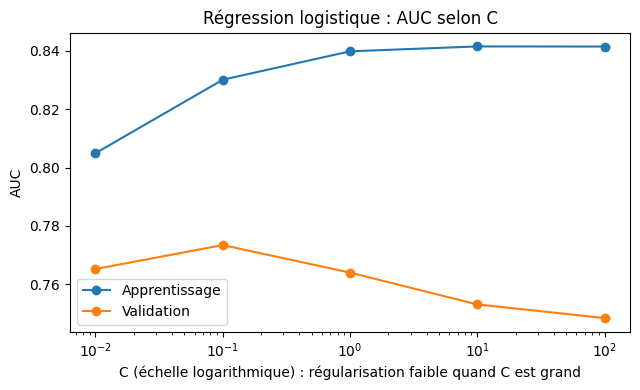

In [61]:
# Courbe de validation : AUC selon C (class_weight = None)
sous = res[res["param_modele__class_weight"].astype(str) == "None"].sort_values("param_modele__C")
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogx(sous["param_modele__C"], sous["mean_train_score"], "o-", label="Apprentissage")
ax.semilogx(sous["param_modele__C"], sous["mean_test_score"], "o-", label="Validation")
ax.set_xlabel("C (échelle logarithmique) : régularisation faible quand C est grand")
ax.set_ylabel("AUC")
ax.set_title("Régression logistique : AUC selon C")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "04_courbe_validation_C.png", dpi=150)
plt.show()

**Interprétation.** Le meilleur réglage est C = 0,1 avec class_weight = None, pour un AUC de validation de 0,773 (référence : 0,500). [Décris ce que tu vois sur ta courbe : l'AUC d'apprentissage monte-t-elle quand C augmente ? L'AUC de validation se stabilise-t-elle ou baisse-t-elle ? Un C trop grand creuse-t-il l'écart entre les deux courbes ?] Cet écart entre apprentissage et validation est le signe de [sous-apprentissage / surapprentissage / peu de surapprentissage].

In [ ]:
from sklearn.base import clone

modele = recherche.best_estimator_            # déjà réentraîné sur tout l'apprentissage
proba_test = modele.predict_proba(X_test)[:, 1]
auc_test = roc_auc_score(y_test, proba_test)

ref.fit(X_train, y_train)
auc_ref_test = roc_auc_score(y_test, ref.predict_proba(X_test)[:, 1])
print(f"AUC test : référence = {auc_ref_test:.3f} | régression logistique = {auc_test:.3f}")

# Coût : faux négatif = 5, faux positif = 1 (hypothèse)
C_FN, C_FP = 5, 1
def cout_total(y_vrai, proba, seuil):
    y_vrai = np.asarray(y_vrai)
    refus = proba >= seuil
    fn = ((~refus) & (y_vrai == 1)).sum()
    fp = (refus & (y_vrai == 0)).sum()
    return int(C_FN * fn + C_FP * fp)

# Seuil choisi sur l'apprentissage, avec des probabilités "hors pli"
p_oof = cross_val_predict(clone(modele), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
seuils = np.linspace(0, 1, 101)
cout_train = [cout_total(y_train, p_oof, s) for s in seuils]
seuil_opt = seuils[int(np.argmin(cout_train))]

n_mauvais, n_bons = int(y_test.sum()), int((1 - y_test).sum())
comparatif = pd.DataFrame({
    "Modèle": ["Référence : tout accepter", "Référence : tout refuser",
               "Régression logistique, seuil 0,5", f"Régression logistique, seuil optimal {seuil_opt:.2f}"],
    "AUC validation": [sc_ref.mean(), sc_ref.mean(), recherche.best_score_, recherche.best_score_],
    "AUC test": [auc_ref_test, auc_ref_test, auc_test, auc_test],
    "Coût test": [C_FN * n_mauvais, C_FP * n_bons,
                  cout_total(y_test, proba_test, 0.5), cout_total(y_test, proba_test, seuil_opt)],
})
print(f"Seuil optimal : {seuil_opt:.2f}")
comparatif.round(3)

AUC test : référence = 0.500 | régression logistique = 0.809
Seuil optimal : 0.22


,Modèle,AUC validation,AUC test,Coût test
0,Référence : tout accepter,0.500,0.500,450
1,Référence : tout refuser,0.500,0.500,210
2,"Régression logistique, seuil 0,5",0.773,0.809,251
3,"Régression logistique, seuil optimal 0.22",0.773,0.809,155


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.plot(seuils, np.array(cout_train) / len(y_train), label="Apprentissage (validation croisée)")
ax.plot(seuils, [cout_total(y_test, proba_test, s) / len(y_test) for s in seuils], label="Test")
ax.axvline(0.5, color="grey", linestyle="--", label="Seuil 0,5")
ax.axvline(seuil_opt, color="red", linestyle=":", label=f"Seuil optimal {seuil_opt:.2f}")
ax.set_xlabel("Seuil de décision (refus si probabilité ≥ seuil)")
ax.set_ylabel("Coût moyen par client (unités de coût)")
ax.set_title("Coût selon le seuil de décision (coûts 5 pour 1)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "05_cout_seuil.png", dpi=150)
plt.show()

**Interprétation.** Le modèle fait nettement mieux que la référence : AUC de test 0,809 contre 0,500 (0,773 en validation, sans écart inquiétant). Au seuil de 0,5, le coût sur le test est de 251 ; au seuil optimal de 0,22, choisi sur l'apprentissage seulement, il tombe à 155, soit **38 % de moins**. Les règles naïves coûtent 450 (tout accepter) et 210 (tout refuser) : le modèle fait aussi mieux que la meilleure d'entre elles (−26 % par rapport à « tout refuser »). Le seuil optimal (0,22) est proche du seuil théorique 1/(1+5) ≈ 0,17. Sur la courbe, le coût est presque plat entre environ 0,1 et 0,27 : le minimum est peu marqué, et plusieurs seuils voisins donneraient un coût proche.

In [ ]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score

for seuil in [0.5, seuil_opt]:
    pred = (proba_test >= seuil).astype(int)
    cm = confusion_matrix(y_test, pred)
    print(f"Seuil {seuil:.2f} : vrais bons {cm[0,0]}, bons refusés {cm[0,1]}, "
          f"mauvais acceptés {cm[1,0]}, mauvais détectés {cm[1,1]} | "
          f"rappel mauvais = {recall_score(y_test, pred):.2f}, précision = {precision_score(y_test, pred):.2f}")

# Les 5 mauvais risques jugés les moins risqués par le modèle (erreurs les plus graves)
erreurs = X_test.assign(reel=y_test, proba_mauvais=proba_test.round(2))
erreurs[erreurs["reel"] == 1].sort_values("proba_mauvais").head(5)[
    ["statut_compte", "duree_mois", "montant", "age", "historique_credit", "proba_mauvais"]]

**Analyse des erreurs.** Au seuil de 0,5, le modèle accepte à tort 47 mauvais risques sur 90 et refuse 16 bons clients (rappel des mauvais risques 0,48, précision 0,73). Au seuil optimal, il n'en accepte plus que 12 (rappel 0,87), mais refuse 95 bons clients (précision 0,45) : c'est le compromis voulu, car un mauvais risque accepté coûte 5 fois plus. Les cinq mauvais risques que le modèle juge les moins risqués (probabilité de 0,09 à 0,12) ont tous un historique de crédit A32, et trois sur cinq ont un compte A14, le statut le plus favorable : ces clients ressemblent à de bons clients selon les variables disponibles, ce qui montre une limite du modèle.

In [ ]:
from sklearn.inspection import permutation_importance

r = permutation_importance(modele, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=GRAINE)
imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(imp.head(8).round(3))

fig, ax = plt.subplots(figsize=(6.5, 4))
imp.head(8)[::-1].plot.barh(ax=ax, color="teal")
ax.set_xlabel("Baisse de l'AUC quand la variable est mélangée")
ax.set_title("Importance par permutation (test)")
plt.tight_layout()
plt.savefig(FIGURES / "06_importance_permutation.png", dpi=150)
plt.show()

**Interprétation des variables.** Mélanger le statut du compte courant fait baisser l'AUC de 0,090, bien plus que toute autre variable (durée 0,035, historique de crédit 0,024, objet 0,024, montant 0,019). Cela rejoint l'exploration : ce statut faisait varier la part de mauvais risques de 12 % à 49 %. Cette mesure indique combien le modèle s'appuie sur une variable, pas dans quel sens ni pour quelle raison : c'est une association, pas une cause. Calculée sur le test, elle sert seulement à l'interprétation, jamais au choix du modèle.

In [ ]:
# Écart apprentissage / test
auc_train = roc_auc_score(y_train, modele.predict_proba(X_train)[:, 1])
print(f"AUC apprentissage = {auc_train:.3f} | AUC test = {auc_test:.3f}")

# Stabilité selon le découpage (5 graines), mêmes hyperparamètres : indication seulement
aucs = []
for graine in [0, 1, 2, 3, 4]:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=graine)
    m = clone(modele).fit(Xtr, ytr)
    aucs.append(roc_auc_score(yte, m.predict_proba(Xte)[:, 1]))
print("AUC test selon la graine :", np.round(aucs, 3))
print(f"Moyenne = {np.mean(aucs):.3f} | écart-type = {np.std(aucs):.3f}")

**Généralisation.** L'AUC d'apprentissage (0,824) est proche de celle du test (0,809) : le surapprentissage est faible. Sur cinq découpages différents, l'AUC de test varie de 0,769 à 0,814 (moyenne 0,797, écart-type 0,016) : le résultat est assez stable. Cette vérification est indicative, car les hyperparamètres ont été choisis sur un seul découpage.

In [ ]:
# Illustration sur 4 dossiers du test (non utilisés pour l'apprentissage) : 2 bons et 2 mauvais risques
idx = list(y_test[y_test == 0].index[:2]) + list(y_test[y_test == 1].index[:2])
echantillon = X_test.loc[idx]
p = modele.predict_proba(echantillon)[:, 1]
tableau_illustration = echantillon[["statut_compte", "duree_mois", "montant", "age"]].assign(
    proba_mauvais=p.round(2),
    decision=np.where(p >= seuil_opt, "Refuser", "Accepter"),
    reel=np.where(y_test.loc[idx] == 1, "Mauvais risque", "Bon risque"))
tableau_illustration

## 7. Résultats
Les résultats détaillés, avec leurs interprétations, sont présentés dans les sections 5 et 6 ci-dessus. Tableau comparatif (test) : voir la cellule « comparatif ».

## 8. Analyse critique
- **Le ratio de coût (5 pour 1) est une hypothèse**, non une donnée réelle : le seuil optimal en dépend directement, et le coût est presque plat entre 0,1 et 0,27, donc le minimum est peu marqué.
- **Petit échantillon** : 300 clients de test dont 90 mauvais risques ; les coûts mesurés sont variables (AUC de test entre 0,769 et 0,814 selon la graine).
- **Un seul découpage** pour le réglage des hyperparamètres.
- **Pas de dimension temporelle** : on ne peut pas tester la robustesse dans le temps ; le jeu est ancien (montants en marks allemands).
- **Biais de sélection possible** : on ne sait pas comment les dossiers ont été choisis.
- **Variables sensibles** (statut personnel et sexe, travailleur étranger) : leur usage soulève des questions d'équité non étudiées ici.
- **Pistes concrètes** : tester plusieurs ratios de coût, répéter la validation croisée, calibrer les probabilités, comparer un modèle non linéaire (forêt aléatoire, gradient boosting), obtenir des coûts réels.

## 9. Conclusion
La régression logistique détecte les mauvais risques bien mieux que la référence : AUC de test de 0,809 contre 0,500. Choisir le seuil selon les coûts (0,22 au lieu de 0,5) réduit le coût de test de 251 à 155, soit 38 %, au prix de 95 bons clients refusés. **L'objectif mesurable est atteint** (AUC ≥ 0,70 et baisse du coût ≥ 20 %). Cette conclusion dépend du ratio de coût supposé (5 pour 1) et d'un échantillon de 1 000 dossiers.

## 10. Références et reproduction
- Hofmann, H. (1994). *Statlog (German Credit Data)*. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/144
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
- Elkan, C. (2001). The foundations of cost-sensitive learning. *IJCAI*, 973-978.
- Dépôt : https://github.com/Fatima5730/25007655-FATIMA-LAMRINI-FIN3

**Pour reproduire :** cloner le dépôt, installer les dépendances (`pip install -r requirements.txt`), ouvrir `notebooks/projet_F1.ipynb` et lancer « Redémarrer et tout exécuter » (environ une minute). Les données sont dans `data/raw/`, les figures sont recréées dans `figures/`.

## Déclaration des ressources et outils d'IA
| Outil ou ressource | Date | Usage précis | Parties concernées | Vérification effectuée |
|---|---|---|---|---|
| Assistant d'IA (Claude) | 17/11/2026 | Aide à la structure du notebook, suggestions de code et de brouillons de texte, explication d'erreurs de chemins | Sections 1 à 10 | Code lu, exécuté et adapté ; chiffres vérifiés dans les sorties |
| Documentation scikit-learn | 17/11/2026 | Paramètres de GridSearchCV et LogisticRegression | Sections 5 et 6 | Testé dans le notebook |

In [ ]:
import shutil
shutil.make_archive("figures_export", "zip", FIGURES)
try:
    from google.colab import files
    files.download("figures_export.zip")
except ImportError:
    print("Archive créée : figures_export.zip")